In [5]:
import pandas as pd

In [6]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd

In [8]:
pd.__version__

'3.1.0'

In [9]:
import os
os.getcwd()


'C:\\Users\\sanja\\OneDrive\\Desktop\\Water-Quality-Analysis\\notebooks'

In [10]:
os.listdir("../data")

['kerala_water_quality.csv']

In [11]:
df = pd.read_csv("../data/kerala_water_quality.csv")

In [12]:
df.shape

(1155, 22)

In [13]:
df.columns

Index(['_id', 'SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'River', 'Basin',
       'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Biochemical Oxygen Demand (mg/L)', 'Chemical Oxygen Demand (mg/L)',
       'Fecal Coliform (MPN/100mL)', 'Total Coliform (MPN/100mL)'],
      dtype='str')

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1155 entries, 0 to 1154
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   _id                               1155 non-null   int64  
 1   SlNo                              1155 non-null   int64  
 2   Station                           1155 non-null   str    
 3   Agency                            1155 non-null   str    
 4   State LGD Code                    1155 non-null   int64  
 5   State                             1155 non-null   str    
 6   District LGD Code                 1155 non-null   int64  
 7   District                          1155 non-null   str    
 8   Tehsil                            1155 non-null   str    
 9   River                             1155 non-null   str    
 10  Basin                             1155 non-null   str    
 11  Tributary                         1155 non-null   str    
 12  Subtributary     

In [15]:
df.isnull().sum()

_id                                    0
SlNo                                   0
Station                                0
Agency                                 0
State LGD Code                         0
State                                  0
District LGD Code                      0
District                               0
Tehsil                                 0
River                                  0
Basin                                  0
Tributary                              0
Subtributary                           0
SubSubtributary                        0
Local River                            0
Latitude                               0
Longitude                              0
Data Acquisition Time                  0
Biochemical Oxygen Demand (mg/L)     499
Chemical Oxygen Demand (mg/L)       1155
Fecal Coliform (MPN/100mL)           272
Total Coliform (MPN/100mL)           862
dtype: int64

In [16]:
(df.isnull().sum() / len(df) * 100).round(2)

_id                                   0.00
SlNo                                  0.00
Station                               0.00
Agency                                0.00
State LGD Code                        0.00
State                                 0.00
District LGD Code                     0.00
District                              0.00
Tehsil                                0.00
River                                 0.00
Basin                                 0.00
Tributary                             0.00
Subtributary                          0.00
SubSubtributary                       0.00
Local River                           0.00
Latitude                              0.00
Longitude                             0.00
Data Acquisition Time                 0.00
Biochemical Oxygen Demand (mg/L)     43.20
Chemical Oxygen Demand (mg/L)       100.00
Fecal Coliform (MPN/100mL)           23.55
Total Coliform (MPN/100mL)           74.63
dtype: float64

In [17]:
df.head()

,_id,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,River,...,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Biochemical Oxygen Demand (mg/L),Chemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL)
0,1,1,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,9.270844,76.535403,01-01-2021 08:30,1.8,NaN,110.0,NaN
1,2,2,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,9.270844,76.535403,09-02-2021 08:30,1.9,NaN,110.0,NaN
2,3,3,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,9.270844,76.535403,12-03-2021 08:30,1.8,NaN,110.0,NaN
3,4,4,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,9.270844,76.535403,03-04-2021 08:30,1.9,NaN,110.0,NaN
4,5,5,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,9.270844,76.535403,06-05-2021 08:30,1.8,NaN,100.0,NaN


In [18]:
df["Data Acquisition Time"].head(10)

0    01-01-2021 08:30
1    09-02-2021 08:30
2    12-03-2021 08:30
3    03-04-2021 08:30
4    06-05-2021 08:30
5    10-06-2021 08:30
6    19-07-2021 08:30
7    15-08-2021 08:30
8    01-09-2021 08:30
9    23-10-2021 08:30
Name: Data Acquisition Time, dtype: str

In [19]:
df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    format="%d-%m-%Y %H:%M"
)

In [20]:
df["Data Acquisition Time"].agg([min,max])

min   2021-01-01 08:30:00
max   2021-12-28 08:30:00
Name: Data Acquisition Time, dtype: datetime64[us]

In [21]:
df["Data Acquisition Time"].dt.month.value_counts().sort_index()

Data Acquisition Time
1      96
2      96
3      92
4     122
5      80
6      89
7      90
8      90
9      92
10    124
11     93
12     91
Name: count, dtype: int64

In [22]:
df["Station"].nunique()

129

In [23]:
df["Station"].value_counts().describe()

count    129.000000
mean       8.953488
std        4.390794
min        1.000000
25%        2.000000
50%       12.000000
75%       12.000000
max       12.000000
Name: count, dtype: float64

In [24]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].describe()

,Biochemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL)
count,656.000000,883.000000,293.000000
mean,2.211280,823.537939,3412.443686
std,1.268428,3223.587417,13805.449667
min,1.100000,4.000000,12.000000
25%,1.500000,79.000000,240.000000
50%,1.900000,130.000000,620.000000
75%,2.400000,490.000000,2200.000000
max,8.200000,70000.000000,200000.000000


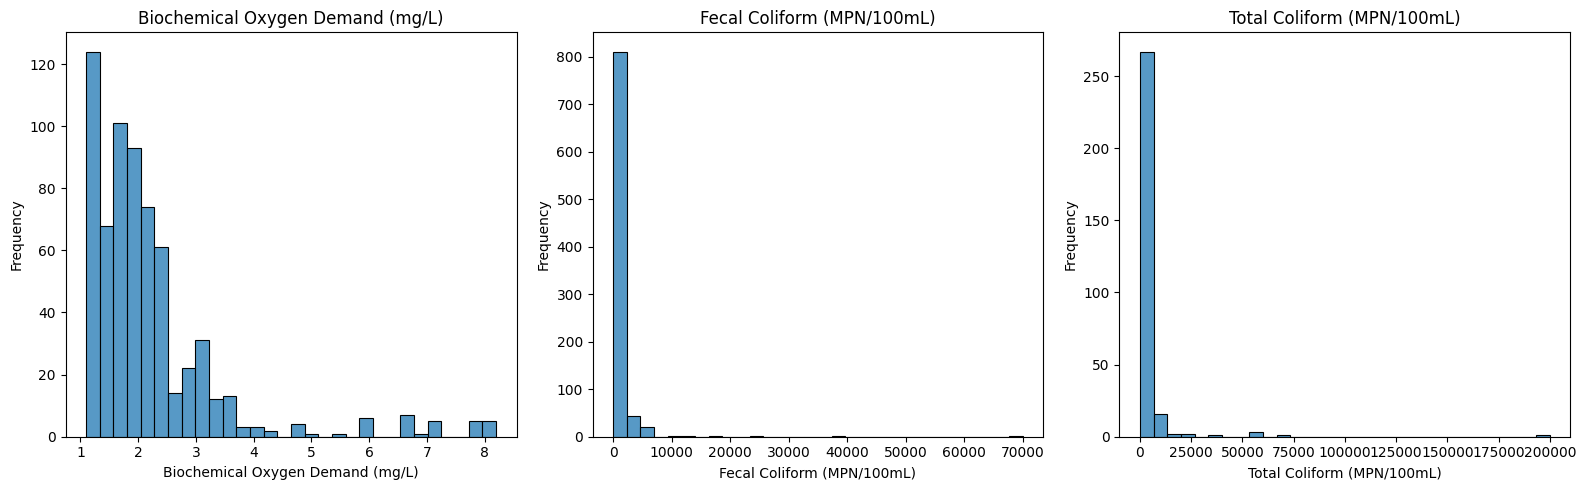

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

columns = [
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]

for column, ax in zip(columns, axes):
    sns.histplot(data=df, x=column, bins=30, ax=ax)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [26]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


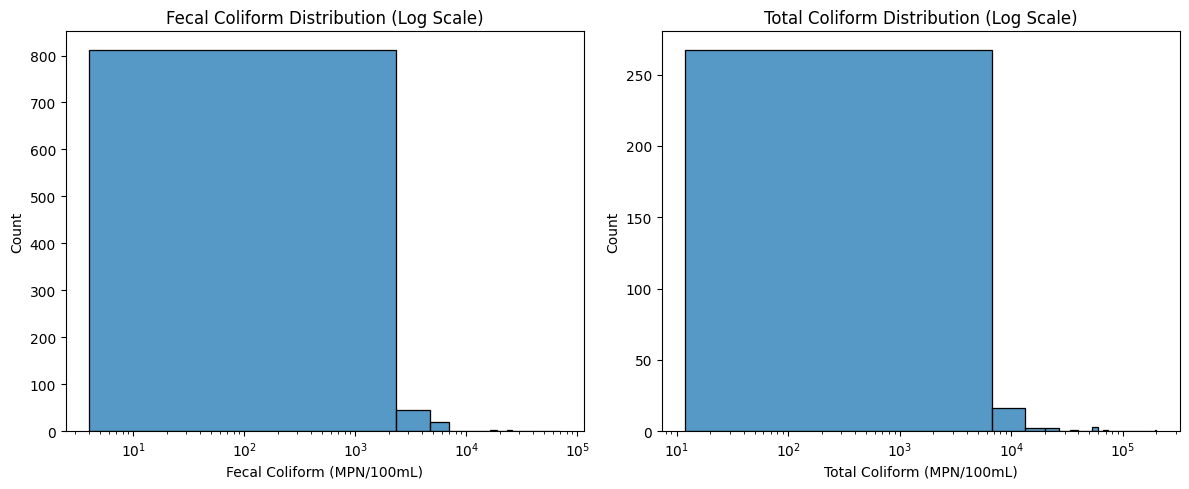

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["Fecal Coliform (MPN/100mL)"], bins=30, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("Fecal Coliform Distribution (Log Scale)")

sns.histplot(df["Total Coliform (MPN/100mL)"], bins=30, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Total Coliform Distribution (Log Scale)")

plt.tight_layout()
plt.show()

In [29]:
(df[[
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]] <= 0).sum()

Fecal Coliform (MPN/100mL)    0
Total Coliform (MPN/100mL)    0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
(df.isnull().mean() * 100).round(2)

_id                                   0.00
SlNo                                  0.00
Station                               0.00
Agency                                0.00
State LGD Code                        0.00
State                                 0.00
District LGD Code                     0.00
District                              0.00
Tehsil                                0.00
River                                 0.00
Basin                                 0.00
Tributary                             0.00
Subtributary                          0.00
SubSubtributary                       0.00
Local River                           0.00
Latitude                              0.00
Longitude                             0.00
Data Acquisition Time                 0.00
Biochemical Oxygen Demand (mg/L)     43.20
Chemical Oxygen Demand (mg/L)       100.00
Fecal Coliform (MPN/100mL)           23.55
Total Coliform (MPN/100mL)           74.63
dtype: float64

In [32]:
df.isnull().sum()

_id                                    0
SlNo                                   0
Station                                0
Agency                                 0
State LGD Code                         0
State                                  0
District LGD Code                      0
District                               0
Tehsil                                 0
River                                  0
Basin                                  0
Tributary                              0
Subtributary                           0
SubSubtributary                        0
Local River                            0
Latitude                               0
Longitude                              0
Data Acquisition Time                  0
Biochemical Oxygen Demand (mg/L)     499
Chemical Oxygen Demand (mg/L)       1155
Fecal Coliform (MPN/100mL)           272
Total Coliform (MPN/100mL)           862
dtype: int64

In [33]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Chemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].isnull().sum(axis=1).value_counts().sort_index()

2    683
3    466
4      6
Name: count, dtype: int64

In [34]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].dropna().shape

(0, 3)

In [35]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].isnull().sum()

Biochemical Oxygen Demand (mg/L)    499
Fecal Coliform (MPN/100mL)          272
Total Coliform (MPN/100mL)          862
dtype: int64

In [36]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].notnull().all(axis=1).sum()

np.int64(0)

In [37]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].notnull().astype(int).value_counts()

Biochemical Oxygen Demand (mg/L)  Fecal Coliform (MPN/100mL)  Total Coliform (MPN/100mL)
1                                 1                           0                             467
0                                 1                           0                             357
1                                 0                           1                             157
0                                 0                           1                              77
                                  1                           1                              59
1                                 0                           0                              32
0                                 0                           0                               6
Name: count, dtype: int64

In [38]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Chemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].isnull().sum()

Biochemical Oxygen Demand (mg/L)     499
Chemical Oxygen Demand (mg/L)       1155
Fecal Coliform (MPN/100mL)           272
Total Coliform (MPN/100mL)           862
dtype: int64

In [39]:
df.drop(columns=["Chemical Oxygen Demand (mg/L)"], inplace=True)

C:\Users\sanja\AppData\Local\Temp\ipykernel_14240\527814013.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Chemical Oxygen Demand (mg/L)"], inplace=True)


In [40]:
df.shape

(1155, 21)

In [41]:
columns = [
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]

for column in columns:
    df[column] = df[column].fillna(df[column].median())

In [42]:
df.isnull().sum()

_id                                 0
SlNo                                0
Station                             0
Agency                              0
State LGD Code                      0
State                               0
District LGD Code                   0
District                            0
Tehsil                              0
River                               0
Basin                               0
Tributary                           0
Subtributary                        0
SubSubtributary                     0
Local River                         0
Latitude                            0
Longitude                           0
Data Acquisition Time               0
Biochemical Oxygen Demand (mg/L)    0
Fecal Coliform (MPN/100mL)          0
Total Coliform (MPN/100mL)          0
dtype: int64

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df.dtypes

_id                                          int64
SlNo                                         int64
Station                                        str
Agency                                         str
State LGD Code                               int64
State                                          str
District LGD Code                            int64
District                                       str
Tehsil                                         str
River                                          str
Basin                                          str
Tributary                                      str
Subtributary                                   str
SubSubtributary                                str
Local River                                    str
Latitude                                   float64
Longitude                                  float64
Data Acquisition Time               datetime64[us]
Biochemical Oxygen Demand (mg/L)           float64
Fecal Coliform (MPN/100mL)     

In [45]:
df.to_csv("../data/kerala_water_quality_cleaned.csv", index=False)

In [46]:
import os

os.path.exists("../data/kerala_water_quality_cleaned.csv")

True

In [47]:
df.describe()

,_id,SlNo,State LGD Code,District LGD Code,Latitude,Longitude,Data Acquisition Time,Biochemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL)
count,1155.000000,1155.000000,1155.0,1155.000000,1155.000000,1155.000000,1155,1155.000000,1155.000000,1155.000000
mean,578.000000,578.000000,32.0,559.781818,10.368094,76.256004,2021-06-25 23:51:21.038961,2.076797,660.211255,1328.386147
min,1.000000,1.000000,32.0,554.000000,8.389375,74.894392,2021-01-01 08:30:00,1.100000,4.000000,12.000000
25%,289.500000,289.500000,32.0,555.000000,9.370489,75.933247,2021-04-03 08:30:00,1.800000,100.000000,620.000000
50%,578.000000,578.000000,32.0,559.000000,10.160483,76.348553,2021-07-02 08:30:00,1.900000,130.000000,620.000000
75%,866.500000,866.500000,32.0,564.000000,11.268106,76.661444,2021-10-04 08:30:00,2.000000,310.000000,620.000000
max,1155.000000,1155.000000,32.0,567.000000,12.712450,77.207625,2021-12-28 08:30:00,8.200000,70000.000000,200000.000000
std,333.564087,333.564087,0.0,4.171893,1.177566,0.551265,NaN,0.967988,2833.529324,7050.053488
